--- 正在计算 lambda = 1.0 ---
求解完成！耗时 5.84 s
--- 正在计算 lambda = 0.5 ---
求解完成！耗时 2.26 s
--- 正在计算 lambda = 0.05 ---
求解完成！耗时 2.23 s
--- 正在计算 lambda = 0.02 ---
求解完成！耗时 2.20 s
--- 正在计算 lambda = 0.01 ---
求解完成！耗时 2.19 s
--- 正在计算 lambda = 0.005 ---
求解完成！耗时 2.17 s


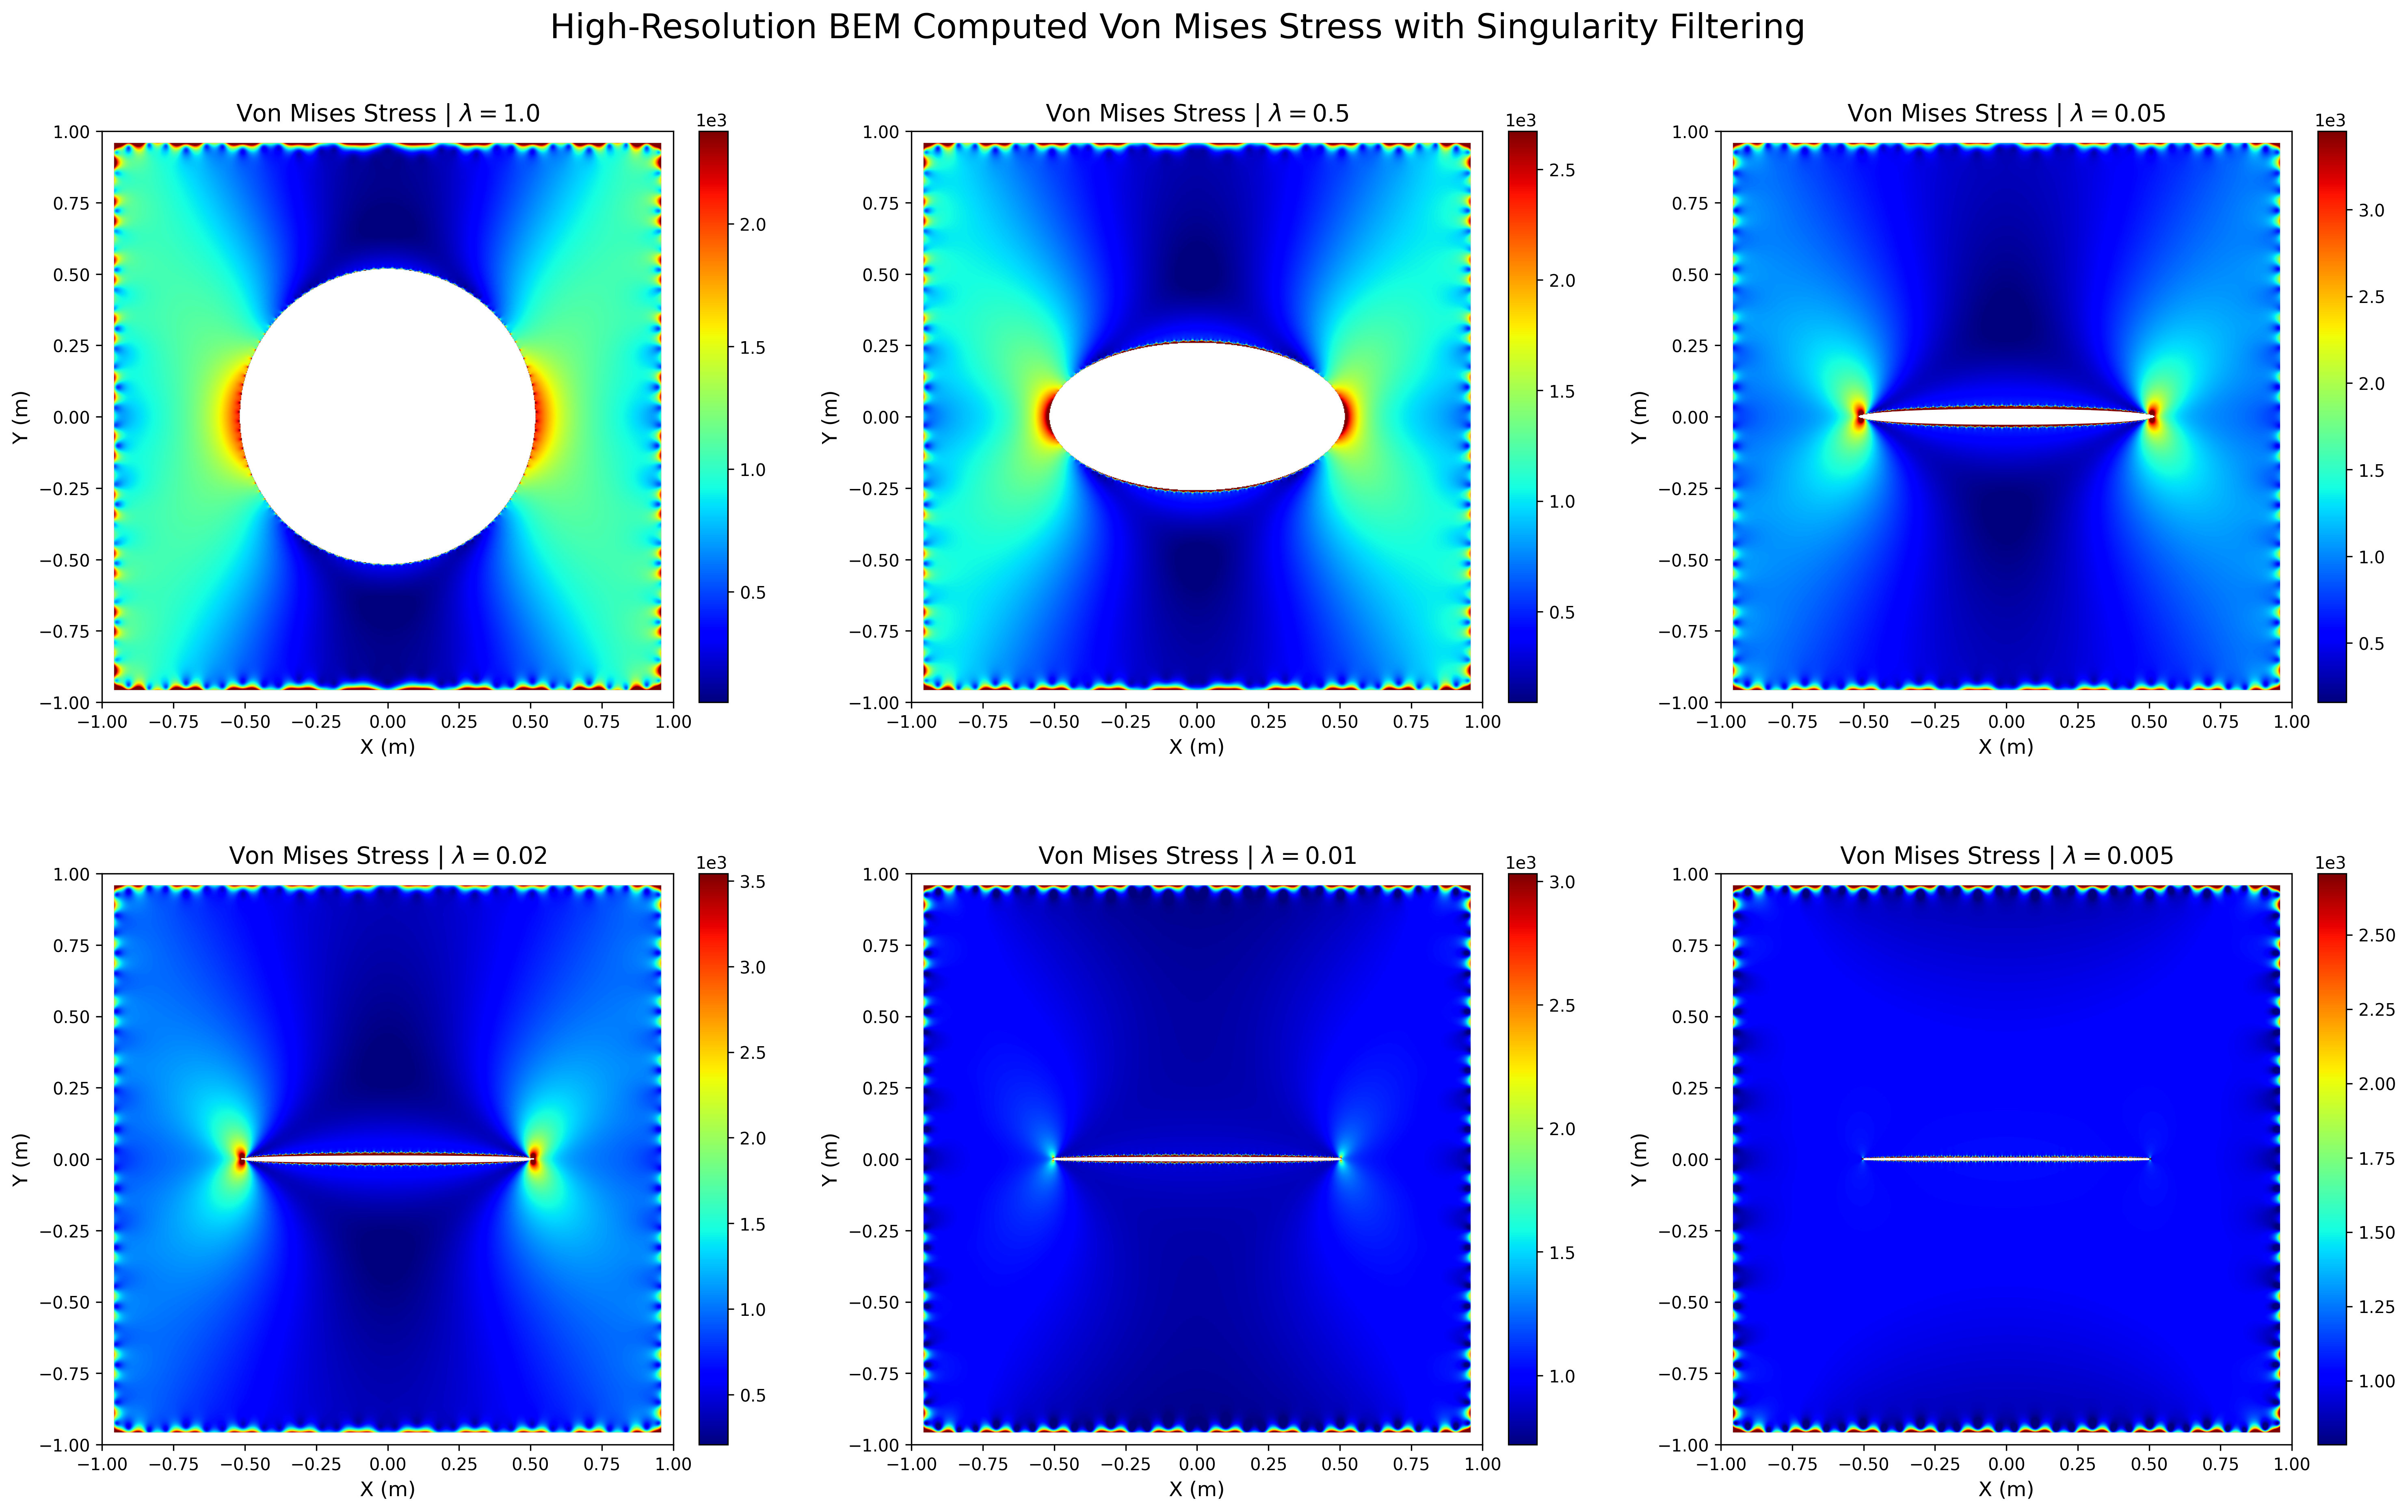

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from numba import njit, prange
import time

# ==========================================
# 1. 物理参数与 BEM 常数定义
# ==========================================
L = 2.0              # 正方形边长 2.0m x 2.0m (坐标范围 -1.0 到 1.0)
E = 1.0e6            # 杨氏模量 1.0 MPa = 1.0e6 Pa
nu = 0.3             # 泊松比
disp_load = 1e-3     # 单侧施加的位移载荷 1.0 mm = 1e-3 m
a_major = 0.5        # 椭圆长半轴固定为 0.5m

# --- 采用平面应力(Plane Stress)假设计算等效参数 ---
nu_eff = nu / (1.0 + nu)
G_shear = E / (2.0 * (1.0 + nu))

# BEM 基本解常数 (提前计算加速)
C1 = 1.0 / (8.0 * np.pi * G_shear * (1.0 - nu_eff))
C2 = 3.0 - 4.0 * nu_eff
C3 = -1.0 / (4.0 * np.pi * (1.0 - nu_eff))
C4 = 1.0 - 2.0 * nu_eff

# 4点高斯积分
gauss_xi, gauss_w = np.polynomial.legendre.leggauss(4)

# ==========================================
# 2. 网格生成函数
# ==========================================
def generate_mesh(lam, n_outer_per_side=10, n_hole=100):
    """
    根据文献要求：外边界共40个单元(每边10个)，椭圆孔100个单元。
    外边界逆时针(CCW)剖分，内边界顺时针(CW)剖分(确保法线指向材料外/即指向孔心)。
    """
    b_minor = a_major * lam
    pts, normals, lengths, edge_ids = [], [], [], []

    # --- 1. 生成外边界 (CCW) ---
    corners = [
        np.array([-L/2, -L/2]), np.array([L/2, -L/2]),  # 0: Bottom
        np.array([L/2, -L/2]),  np.array([L/2, L/2]),   # 1: Right
        np.array([L/2, L/2]),   np.array([-L/2, L/2]),  # 2: Top
        np.array([-L/2, L/2]),  np.array([-L/2, -L/2])  # 3: Left
    ]
    for eid in range(4):
        p_start, p_end = corners[2*eid], corners[2*eid + 1]
        vec = p_end - p_start
        L_seg = np.linalg.norm(vec)
        dl = L_seg / n_outer_per_side
        t = vec / L_seg
        n = np.array([t[1], -t[0]]) # 外法线
        for i in range(n_outer_per_side):
            pts.append(p_start + (i + 0.5) * dl * t)
            normals.append(n); lengths.append(dl); edge_ids.append(eid)

    # --- 2. 生成内部椭圆孔边界 (CW 顺时针) ---
    theta = np.linspace(2*np.pi, 0, n_hole + 1)
    for i in range(n_hole):
        t1, t2 = theta[i], theta[i+1]
        p1 = np.array([a_major * np.cos(t1), b_minor * np.sin(t1)])
        p2 = np.array([a_major * np.cos(t2), b_minor * np.sin(t2)])
        vec = p2 - p1
        L_seg = np.linalg.norm(vec)
        t = vec / L_seg
        n = np.array([t[1], -t[0]]) # 指向孔内部的外法线
        pts.append((p1 + p2) / 2.0)
        normals.append(n); lengths.append(L_seg); edge_ids.append(4)
        
    return np.array(pts), np.array(normals), np.array(lengths), np.array(edge_ids)

# ==========================================
# 3. Numba 极速矩阵组装与内部场计算内核
# ==========================================
@njit(parallel=True)
def assemble_HG_numba(nodes, normals, lengths, gauss_xi, gauss_w, C1, C2, C3, C4):
    N = nodes.shape[0]
    H = np.zeros((2*N, 2*N)); G = np.zeros((2*N, 2*N))
    n_gauss = len(gauss_xi)
    for i in prange(N):
        x_src = nodes[i]
        for j in range(N):
            L_j = lengths[j]
            nx, ny = normals[j, 0], normals[j, 1]
            tx, ty = -ny, nx
            r0, r1 = 2*i, 2*i+1
            c0, c1 = 2*j, 2*j+1
            
            if i == j:
                H[r0, c0] = 0.5; H[r0, c1] = 0.0
                H[r1, c0] = 0.0; H[r1, c1] = 0.5
                g00 = C1 * L_j * (C2 * (1.0 - np.log(L_j/2.0)) + 1.0)
                g11 = C1 * L_j * (C2 * (1.0 - np.log(L_j/2.0)))
                G[r0, c0] = tx*(g00*tx) + nx*(g11*nx); G[r0, c1] = tx*(g00*ty) + nx*(g11*ny)
                G[r1, c0] = ty*(g00*tx) + ny*(g11*nx); G[r1, c1] = ty*(g00*ty) + ny*(g11*ny)
            else:
                y_center = nodes[j]
                H00 = H01 = H10 = H11 = 0.0
                G00 = G01 = G10 = G11 = 0.0
                for g in range(n_gauss):
                    y_gpx = y_center[0] + 0.5 * L_j * gauss_xi[g] * tx
                    y_gpy = y_center[1] + 0.5 * L_j * gauss_xi[g] * ty
                    rx = y_gpx - x_src[0]; ry = y_gpy - x_src[1]
                    r = np.sqrt(rx**2 + ry**2)
                    rdx, rdy = rx / r, ry / r
                    dr_dn = rdx * nx + rdy * ny
                    log_1_r = np.log(1.0 / r)
                    hw = 0.5 * L_j * gauss_w[g]
                    
                    G00 += C1 * (C2 * log_1_r + rdx*rdx) * hw
                    G01 += C1 * (rdx*rdy) * hw
                    G10 += C1 * (rdx*rdy) * hw
                    G11 += C1 * (C2 * log_1_r + rdy*rdy) * hw
                    
                    H00 += C3/r * (dr_dn*(C4 + 2*rdx*rdx) - C4*(rdx*nx - rdx*nx)) * hw
                    H01 += C3/r * (dr_dn*(2*rdx*rdy) - C4*(rdx*ny - rdy*nx)) * hw
                    H10 += C3/r * (dr_dn*(2*rdy*rdx) - C4*(rdy*nx - rdx*ny)) * hw
                    H11 += C3/r * (dr_dn*(C4 + 2*rdy*rdy) - C4*(rdy*ny - rdy*ny)) * hw
                H[r0, c0] = H00; H[r0, c1] = H01; H[r1, c0] = H10; H[r1, c1] = H11
                G[r0, c0] = G00; G[r0, c1] = G01; G[r1, c0] = G10; G[r1, c1] = G11
    return H, G

@njit(parallel=True)
def calc_internal_u_numba(pts, nodes, normals, lengths, gauss_xi, gauss_w, C1, C2, C3, C4, u_bnd, t_bnd):
    N_pts, N, n_gauss = pts.shape[0], nodes.shape[0], len(gauss_xi)
    u_out = np.zeros((N_pts, 2))
    for q in prange(N_pts):
        xi_x, xi_y = pts[q, 0], pts[q, 1]
        u_x = 0.0; u_y = 0.0
        for j in range(N):
            y_center = nodes[j]; L_j = lengths[j]
            nx, ny = normals[j, 0], normals[j, 1]
            tx, ty = -ny, nx
            U00 = U01 = U10 = U11 = 0.0
            T00 = T01 = T10 = T11 = 0.0
            for g in range(n_gauss):
                y_gpx = y_center[0] + 0.5 * L_j * gauss_xi[g] * tx
                y_gpy = y_center[1] + 0.5 * L_j * gauss_xi[g] * ty
                rx, ry = y_gpx - xi_x, y_gpy - xi_y
                r = np.sqrt(rx**2 + ry**2)
                rdx, rdy = rx / r, ry / r
                dr_dn = rdx * nx + rdy * ny
                log_1_r = np.log(1.0 / r)
                hw = 0.5 * L_j * gauss_w[g]
                
                U00 += C1 * (C2 * log_1_r + rdx*rdx) * hw
                U01 += C1 * (rdx*rdy) * hw
                U10 += C1 * (rdx*rdy) * hw
                U11 += C1 * (C2 * log_1_r + rdy*rdy) * hw
                
                T00 += C3/r * (dr_dn*(C4 + 2*rdx*rdx) - C4*(rdx*nx - rdx*nx)) * hw
                T01 += C3/r * (dr_dn*(2*rdx*rdy) - C4*(rdx*ny - rdy*nx)) * hw
                T10 += C3/r * (dr_dn*(2*rdy*rdx) - C4*(rdy*nx - rdx*ny)) * hw
                T11 += C3/r * (dr_dn*(C4 + 2*rdy*rdy) - C4*(rdy*ny - rdy*ny)) * hw
            
            uj_x, uj_y = u_bnd[2*j], u_bnd[2*j+1]
            tj_x, tj_y = t_bnd[2*j], t_bnd[2*j+1]
            u_x += (U00*tj_x + U01*tj_y) - (T00*uj_x + T01*uj_y)
            u_y += (U10*tj_x + U11*tj_y) - (T10*uj_x + T11*uj_y)
        u_out[q, 0], u_out[q, 1] = u_x, u_y
    return u_out

# ==========================================
# 4. 主求解流程封装
# ==========================================
def solve_bem_case(lam):
    print(f"--- 正在计算 lambda = {lam} ---")
    t0 = time.time()
    b_minor = a_major * lam
    nodes, normals, lengths, edge_ids = generate_mesh(lam, 10, 100)
    N = len(nodes)
    
    H, G = assemble_HG_numba(nodes, normals, lengths, gauss_xi, gauss_w, C1, C2, C3, C4)
    
    # --- 施加边界条件 ---
    A = np.zeros((2*N, 2*N)); B = np.zeros(2*N)
    u_known = np.zeros(2*N, dtype=bool); u_val = np.zeros(2*N)
    t_known = np.zeros(2*N, dtype=bool); t_val = np.zeros(2*N)
    
    for i in range(N):
        eid = edge_ids[i]
        dof_x, dof_y = 2*i, 2*i+1
        
        # 为了与文献一致（消除刚体位移并在四个角产生应力集中），顶部和底部必须完全固支拉伸
        if eid == 0:   # 底部 (y = -1.0)
            u_known[dof_x] = True; u_val[dof_x] = 0.0          # X方向锁死
            u_known[dof_y] = True; u_val[dof_y] = -disp_load   # Y方向向下
        elif eid == 2: # 顶部 (y = 1.0)
            u_known[dof_x] = True; u_val[dof_x] = 0.0          # X方向锁死
            u_known[dof_y] = True; u_val[dof_y] = disp_load    # Y方向向上
        else:          # 左右边界与内孔洞，牵引力全为0
            t_known[dof_x] = True; t_val[dof_x] = 0.0
            t_known[dof_y] = True; t_val[dof_y] = 0.0

    for k in range(2*N):
        if u_known[k]:
            A[:, k] = -G[:, k]; B -= H[:, k] * u_val[k]
        else:
            A[:, k] = H[:, k]; B += G[:, k] * t_val[k]
            
    X = np.linalg.solve(A, B)
    u_bnd = np.where(u_known, u_val, X)
    t_bnd = np.where(u_known, X, t_val)
    
    # --- 计算全域应力场 ---
    grid_size = 800  # 从 250 提升至 800 以获得高清分辨率
    coords_1d = np.linspace(-0.99, 0.99, grid_size) # 避免贴边
    XX, YY = np.meshgrid(coords_1d, coords_1d)
    internal_pts = np.c_[XX.ravel(), YY.ravel()]
    
    eps_delta = 1e-4 # 有限差分步长
    u_px = calc_internal_u_numba(internal_pts + np.array([eps_delta, 0.0]), nodes, normals, lengths, gauss_xi, gauss_w, C1, C2, C3, C4, u_bnd, t_bnd)
    u_mx = calc_internal_u_numba(internal_pts - np.array([eps_delta, 0.0]), nodes, normals, lengths, gauss_xi, gauss_w, C1, C2, C3, C4, u_bnd, t_bnd)
    u_py = calc_internal_u_numba(internal_pts + np.array([0.0, eps_delta]), nodes, normals, lengths, gauss_xi, gauss_w, C1, C2, C3, C4, u_bnd, t_bnd)
    u_my = calc_internal_u_numba(internal_pts - np.array([0.0, eps_delta]), nodes, normals, lengths, gauss_xi, gauss_w, C1, C2, C3, C4, u_bnd, t_bnd)

    du_dx = (u_px - u_mx) / (2*eps_delta)
    du_dy = (u_py - u_my) / (2*eps_delta)
    
    eps_xx = du_dx[:, 0]; eps_yy = du_dy[:, 1]; eps_xy = 0.5 * (du_dx[:, 1] + du_dy[:, 0])
    
    # 平面应力 (Plane Stress) 应力恢复公式
    factor = E / (1.0 - nu**2)
    sig_xx = factor * (eps_xx + nu * eps_yy)
    sig_yy = factor * (eps_yy + nu * eps_xx)
    sig_xy = E / (1.0 + nu) * eps_xy
    
    von_mises = np.sqrt(sig_xx**2 - sig_xx*sig_yy + sig_yy**2 + 3 * sig_xy**2)
    von_mises = von_mises.reshape(grid_size, grid_size)
    
    # --- 核心操作：安全遮罩以避免边界奇异性毁掉云图 ---
    dist_ellipse = (XX**2 / (a_major**2)) + (YY**2 / (b_minor**2))
    mask_inside = dist_ellipse <= 1.05  # 挖掉孔及孔边极其贴近处
    mask_outer = (np.abs(XX) > 0.95) | (np.abs(YY) > 0.95) # 挖掉外边界非常贴近处
    
    von_mises[mask_inside | mask_outer] = np.nan
    
    print(f"求解完成！耗时 {time.time()-t0:.2f} s")
    return von_mises, XX, YY

# ==========================================
# 5. 循环执行与批量出图
# ==========================================
# 补充你需要的极限裂纹情况
lams = [1.0, 0.5, 0.05, 0.02, 0.01, 0.005]
results = []

for lam in lams:
    vm_stress, XX, YY = solve_bem_case(lam)
    results.append(vm_stress)

# 统一绘制结果，调整为 2 行 3 列的高清大图
fig = plt.figure(figsize=(24, 14), dpi=300) # 提升画布尺寸和整体 DPI
gs = gridspec.GridSpec(2, 3, figure=fig, wspace=0.25, hspace=0.3)
extent = [-L/2, L/2, -L/2, L/2]

for idx, lam in enumerate(lams):
    # 动态计算当前图表的行和列索引
    row = idx // 3
    col = idx % 3
    ax = fig.add_subplot(gs[row, col])
    
    data = results[idx]
    
    # 使用 99.5% 分位数切断极大奇异值
    vmax = np.nanpercentile(data, 99.5) 
    vmin = np.nanpercentile(data, 1.0)
    
    im = ax.imshow(data, origin='lower', extent=extent, cmap='jet', 
                   aspect='equal', vmax=vmax, vmin=vmin)
    
    # 绘制纯白色的椭圆挡住中间空缺部分
    ellipse = plt.matplotlib.patches.Ellipse((0,0), 2*a_major, 2*(a_major*lam), 
                                             color='white', zorder=10)
    ax.add_patch(ellipse)
    
    ax.set_title(f'Von Mises Stress | $\lambda = {lam}$', fontsize=14)
    ax.set_xlabel('X (m)', fontsize=12)
    ax.set_ylabel('Y (m)', fontsize=12)
    ax.set_facecolor('#ffffff')
    
    cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    cbar.formatter.set_powerlimits((0, 0))

plt.suptitle("High-Resolution BEM Computed Von Mises Stress with Singularity Filtering", fontsize=20, y=0.95)
plt.savefig("high_res_bem_results.png", bbox_inches='tight') # 自动保存高清图片到本地
plt.show()

## Corrected KM-PIKFNN implementation

This version makes the numerical model consistent with the boundary-value problem and the algorithm in Chapter 3.

- The physical square is at $x,y=\pm1$, whereas the outer fictitious sources are placed on a separate artificial square at $x,y=\pm1.25$.
- For ordinary holes, the inner sources remain inside the excluded hole; at $\lambda=1$ they form a concentric circle of radius $0.7a$.
- For $\lambda<0.2$, the squeezed physical inner-source curve is removed. The ellipse is mapped to $|\zeta|=1$, 64 analytic kernels are placed uniformly on the fixed auxiliary circle $|\eta|=0.85$, and low-order Laurent enrichment is added. Hence the inner basis does not collapse as $\lambda\to0$.
- Both prescribed displacement components are enforced on the upper and lower boundaries: $u_x=0$ and $u_y=\pm u_0$.
- For ordinary holes, the traction-free condition is enforced pointwise. For mapped slender holes, the numerically better-conditioned KM boundary relation $\phi+z\overline{\phi'}+\overline{\psi}=C$ is imposed on the unit-circle parameterization.
- A logarithmically refined tip profile is exported so that gradients below the resolution of the Cartesian contour grid are not missed.
- The fixed-source KM network is linear in its output coefficients. This notebook identifies the coefficients with an Adam warm-up followed by L-BFGS refinement; column scaling, exact null-space constraints, and a small ridge term are retained to suppress ill-conditioning.


In [2]:
"""Corrected KM-PIKFNN solver for a square plate with a central elliptical hole.

The approximation uses KM point-force fundamental-solution kernels.  For
moderate aspect ratios, fictitious sources are placed on an inner curve inside
the excluded hole and on an artificial square outside the physical square.  For
highly flattened holes, the squeezed physical inner curve is replaced by a
fixed source circle in the Joukowski plane, supplemented by inverse-power
analytic enrichment functions.

For fixed source locations, all boundary residuals are linear in the kernel
coefficients.  The coefficients are therefore identified by a column-scaled,
regularized least-squares solve.  This minimizes the same boundary loss without
thousands of Adam/L-BFGS iterations.
"""

import argparse
import csv
import time
from dataclasses import dataclass
from pathlib import Path
from typing import Dict, List, Tuple

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Ellipse, Rectangle


# -----------------------------------------------------------------------------
# Physical parameters and nondimensionalization (plane stress)
# -----------------------------------------------------------------------------
L = 2.0
E_REAL = 1.0e6
NU = 0.3
U0_REAL = 1.0e-3
A_MAJOR = 0.5

U_SCALE = 1.0e3
E = E_REAL / 1.0e6
U0 = U0_REAL * U_SCALE
KAPPA = (3.0 - NU) / (1.0 + NU)
G = E / (2.0 * (1.0 + NU))
STRESS_TO_PA = E_REAL / U_SCALE
C0 = 2.0 * np.pi * (KAPPA + 1.0)


@dataclass
class SolverConfig:
    n_side: int = 280
    n_hole: int = 720
    n_inner_sources: int = 96
    n_outer_sources_per_side: int = 24
    inner_source_scale: float = 0.70
    outer_source_scale: float = 1.25
    mapped_lambda_threshold: float = 0.20
    n_mapped_sources: int = 64
    mapped_source_radius: float = 0.85
    w_displacement: float = 20.0
    w_side_traction: float = 3.0
    w_hole_traction: float = 15.0
    ridge_relative: float = 1.0e-8
    adam_steps: int = 1500
    adam_lr: float = 5.0e-2
    lbfgs_steps: int = 300
    optimizer_seed: int = 1234


def pole_order_for_lambda(lam: float) -> int:
    """Analytic enrichment used only when the ellipse becomes crack-like."""
    if lam >= 0.20:
        return 0
    if lam >= 0.05:
        return 8
    if lam >= 0.02:
        return 12
    return 16


def build_source_points(lam: float, cfg: SolverConfig) -> Tuple[np.ndarray, int, bool]:
    """Return physical-plane sources and select the mapped-circle representation."""
    b_minor = A_MAJOR * lam
    use_mapped_inner = lam < cfg.mapped_lambda_threshold

    if use_mapped_inner:
        # The inner representation is constructed on a fixed auxiliary circle;
        # no physical source curve is squeezed as lambda tends to zero.
        inner = np.empty(0, dtype=np.complex128)
        n_inner = 0
    else:
        n_inner = cfg.n_inner_sources
        # For lambda=1 this is exactly a concentric circle of radius 0.7a.
        theta = (np.arange(n_inner, dtype=float) + 0.5) * (2.0 * np.pi / n_inner)
        inner = (
            cfg.inner_source_scale * A_MAJOR * np.cos(theta)
            + 1j * cfg.inner_source_scale * b_minor * np.sin(theta)
        )

    # Artificial square: x,y = +/- alpha*L/2, alpha>1.  These are not physical
    # boundary points.  Endpoints are trimmed so no source is duplicated at a corner.
    n_outer = cfg.n_outer_sources_per_side
    extent = cfg.outer_source_scale * (L / 2.0)
    values = np.linspace(-extent, extent, n_outer + 2, dtype=float)[1:-1]
    outer = np.concatenate(
        [
            values - 1j * extent,
            extent + 1j * values,
            values[::-1] + 1j * extent,
            -extent + 1j * values[::-1],
        ]
    )

    sources = np.concatenate([inner, outer]).astype(np.complex128)
    assert np.all(np.maximum(np.abs(outer.real), np.abs(outer.imag)) > L / 2.0)
    if n_inner:
        assert np.all((inner.real / A_MAJOR) ** 2 + (inner.imag / b_minor) ** 2 < 1.0)
    return sources, n_inner, use_mapped_inner


def joukowski_inverse(z: np.ndarray, lam: float) -> Tuple[np.ndarray, np.ndarray, np.ndarray]:
    """Exterior inverse map and its first two derivatives with respect to z."""
    z = np.asarray(z, dtype=np.complex128).reshape(-1, 1)
    c1 = 0.5 * A_MAJOR * (1.0 + lam)
    c2 = 0.5 * A_MAJOR * (1.0 - lam)
    discriminant = np.sqrt(z**2 - 4.0 * c1 * c2)
    root_1 = (z + discriminant) / (2.0 * c1)
    root_2 = (z - discriminant) / (2.0 * c1)
    zeta = np.where(np.abs(root_1) >= np.abs(root_2), root_1, root_2)

    map_zeta = c1 - c2 / zeta**2
    map_zeta_zeta = 2.0 * c2 / zeta**3
    zeta_z = 1.0 / map_zeta
    zeta_zz = -map_zeta_zeta / map_zeta**3
    return zeta, zeta_z, zeta_zz


def point_force_influence(z: np.ndarray, sources: np.ndarray) -> Tuple[np.ndarray, ...]:
    """Influence matrices for real kernel coefficients and four far-field terms."""
    z = np.asarray(z, dtype=np.complex128).reshape(-1, 1)
    source_row = sources.reshape(1, -1)
    q = z - source_row
    log_q = np.log(q)
    n_points = z.shape[0]
    n_sources = source_row.shape[1]
    n_coefficients = 2 * n_sources + 4

    phi_kernel = -log_q / C0
    phi_z_kernel = -1.0 / (C0 * q)
    phi_zz_kernel = 1.0 / (C0 * q**2)
    psi_conjugate_kernel = KAPPA * log_q / C0
    psi_kernel = np.conj(source_row) / (C0 * q)
    psi_z_conjugate_kernel = KAPPA / (C0 * q)
    psi_z_kernel = -np.conj(source_row) / (C0 * q**2)

    phi = np.zeros((n_points, n_coefficients), dtype=np.complex128)
    phi_z = np.zeros_like(phi)
    phi_zz = np.zeros_like(phi)
    psi = np.zeros_like(phi)
    psi_z = np.zeros_like(phi)

    # P_m = a_m + i b_m.
    phi[:, :n_sources] = phi_kernel
    phi[:, n_sources : 2 * n_sources] = 1j * phi_kernel
    phi_z[:, :n_sources] = phi_z_kernel
    phi_z[:, n_sources : 2 * n_sources] = 1j * phi_z_kernel
    phi_zz[:, :n_sources] = phi_zz_kernel
    phi_zz[:, n_sources : 2 * n_sources] = 1j * phi_zz_kernel

    psi[:, :n_sources] = psi_conjugate_kernel + psi_kernel
    psi[:, n_sources : 2 * n_sources] = 1j * (psi_kernel - psi_conjugate_kernel)
    psi_z[:, :n_sources] = psi_z_conjugate_kernel + psi_z_kernel
    psi_z[:, n_sources : 2 * n_sources] = 1j * (
        psi_z_kernel - psi_z_conjugate_kernel
    )

    # Linear far-field potentials phi_inf*z and psi_inf*z.
    phi[:, 2 * n_sources] = z[:, 0]
    phi_z[:, 2 * n_sources] = 1.0
    phi[:, 2 * n_sources + 1] = 1j * z[:, 0]
    phi_z[:, 2 * n_sources + 1] = 1j
    psi[:, 2 * n_sources + 2] = z[:, 0]
    psi_z[:, 2 * n_sources + 2] = 1.0
    psi[:, 2 * n_sources + 3] = 1j * z[:, 0]
    psi_z[:, 2 * n_sources + 3] = 1j

    displacement = (
        KAPPA * phi - z * np.conj(phi_z) - np.conj(psi)
    ) / (2.0 * G)
    stress_sum = 4.0 * phi_z.real
    stress_difference = 2.0 * (np.conj(z) * phi_zz + psi_z)
    sigma_xx = 0.5 * (stress_sum - stress_difference.real)
    sigma_yy = 0.5 * (stress_sum + stress_difference.real)
    sigma_xy = 0.5 * stress_difference.imag
    return displacement.real, displacement.imag, sigma_xx, sigma_yy, sigma_xy


def point_force_resultant_influence(z: np.ndarray, sources: np.ndarray) -> np.ndarray:
    """Influence matrix of phi + z*conj(phi') + conj(psi)."""
    z = np.asarray(z, dtype=np.complex128).reshape(-1, 1)
    source_row = sources.reshape(1, -1)
    q = z - source_row
    log_q = np.log(q)
    n_points = z.shape[0]
    n_sources = source_row.shape[1]
    n_coefficients = 2 * n_sources + 4

    phi_kernel = -log_q / C0
    phi_z_kernel = -1.0 / (C0 * q)
    psi_conjugate_kernel = KAPPA * log_q / C0
    psi_kernel = np.conj(source_row) / (C0 * q)

    phi = np.zeros((n_points, n_coefficients), dtype=np.complex128)
    phi_z = np.zeros_like(phi)
    psi = np.zeros_like(phi)
    phi[:, :n_sources] = phi_kernel
    phi[:, n_sources : 2 * n_sources] = 1j * phi_kernel
    phi_z[:, :n_sources] = phi_z_kernel
    phi_z[:, n_sources : 2 * n_sources] = 1j * phi_z_kernel
    psi[:, :n_sources] = psi_conjugate_kernel + psi_kernel
    psi[:, n_sources : 2 * n_sources] = 1j * (psi_kernel - psi_conjugate_kernel)
    phi[:, 2 * n_sources] = z[:, 0]
    phi_z[:, 2 * n_sources] = 1.0
    phi[:, 2 * n_sources + 1] = 1j * z[:, 0]
    phi_z[:, 2 * n_sources + 1] = 1j
    psi[:, 2 * n_sources + 2] = z[:, 0]
    psi[:, 2 * n_sources + 3] = 1j * z[:, 0]
    return phi + z * np.conj(phi_z) + np.conj(psi)


def pole_influence(z: np.ndarray, lam: float, order: int) -> Tuple[np.ndarray, ...]:
    """Joukowski inverse-power enrichment, analytic in the material domain."""
    z = np.asarray(z, dtype=np.complex128).reshape(-1, 1)
    zeta, zeta_z, zeta_zz = joukowski_inverse(z, lam)
    powers = np.arange(1, order + 1, dtype=float).reshape(1, -1)

    basis = zeta ** (-powers)
    basis_zeta = -powers * zeta ** (-powers - 1.0)
    basis_zeta_zeta = powers * (powers + 1.0) * zeta ** (-powers - 2.0)
    basis_z = basis_zeta * zeta_z
    basis_zz = basis_zeta_zeta * zeta_z**2 + basis_zeta * zeta_zz

    zero = np.zeros_like(basis)
    phi = np.concatenate([basis, 1j * basis, zero, zero], axis=1)
    phi_z = np.concatenate([basis_z, 1j * basis_z, zero, zero], axis=1)
    phi_zz = np.concatenate([basis_zz, 1j * basis_zz, zero, zero], axis=1)
    psi = np.concatenate([zero, zero, basis, 1j * basis], axis=1)
    psi_z = np.concatenate([zero, zero, basis_z, 1j * basis_z], axis=1)

    displacement = (
        KAPPA * phi - z * np.conj(phi_z) - np.conj(psi)
    ) / (2.0 * G)
    stress_sum = 4.0 * phi_z.real
    stress_difference = 2.0 * (np.conj(z) * phi_zz + psi_z)
    sigma_xx = 0.5 * (stress_sum - stress_difference.real)
    sigma_yy = 0.5 * (stress_sum + stress_difference.real)
    sigma_xy = 0.5 * stress_difference.imag
    return displacement.real, displacement.imag, sigma_xx, sigma_yy, sigma_xy


def pole_resultant_influence(z: np.ndarray, lam: float, order: int) -> np.ndarray:
    z = np.asarray(z, dtype=np.complex128).reshape(-1, 1)
    zeta, zeta_z, _ = joukowski_inverse(z, lam)
    powers = np.arange(1, order + 1, dtype=float).reshape(1, -1)
    basis = zeta ** (-powers)
    basis_z = (-powers * zeta ** (-powers - 1.0)) * zeta_z
    zero = np.zeros_like(basis)
    phi = np.concatenate([basis, 1j * basis, zero, zero], axis=1)
    phi_z = np.concatenate([basis_z, 1j * basis_z, zero, zero], axis=1)
    psi = np.concatenate([zero, zero, basis, 1j * basis], axis=1)
    return phi + z * np.conj(phi_z) + np.conj(psi)


def mapped_circle_influence(
    z: np.ndarray,
    lam: float,
    n_kernels: int,
    source_radius: float,
) -> Tuple[np.ndarray, ...]:
    """Analytic rational kernels with uniformly spaced centers in the zeta-plane.

    The physical ellipse is mapped to |zeta|=1.  Kernel centers remain on the
    fixed circle |eta|=source_radius<1, so they do not collapse when lambda is
    reduced.  The chain-rule factors naturally amplify the near-tip gradients.
    """
    z = np.asarray(z, dtype=np.complex128).reshape(-1, 1)
    zeta, zeta_z, zeta_zz = joukowski_inverse(z, lam)
    theta = (np.arange(n_kernels, dtype=float) + 0.5) * (2.0 * np.pi / n_kernels)
    eta = (source_radius * np.exp(1j * theta)).reshape(1, -1)

    q = zeta - eta
    basis = 1.0 / q
    basis_zeta = -1.0 / q**2
    basis_zeta_zeta = 2.0 / q**3
    basis_z = basis_zeta * zeta_z
    basis_zz = basis_zeta_zeta * zeta_z**2 + basis_zeta * zeta_zz

    zero = np.zeros_like(basis)
    phi = np.concatenate([basis, 1j * basis, zero, zero], axis=1)
    phi_z = np.concatenate([basis_z, 1j * basis_z, zero, zero], axis=1)
    phi_zz = np.concatenate([basis_zz, 1j * basis_zz, zero, zero], axis=1)
    psi = np.concatenate([zero, zero, basis, 1j * basis], axis=1)
    psi_z = np.concatenate([zero, zero, basis_z, 1j * basis_z], axis=1)

    displacement = (
        KAPPA * phi - z * np.conj(phi_z) - np.conj(psi)
    ) / (2.0 * G)
    stress_sum = 4.0 * phi_z.real
    stress_difference = 2.0 * (np.conj(z) * phi_zz + psi_z)
    sigma_xx = 0.5 * (stress_sum - stress_difference.real)
    sigma_yy = 0.5 * (stress_sum + stress_difference.real)
    sigma_xy = 0.5 * stress_difference.imag
    return displacement.real, displacement.imag, sigma_xx, sigma_yy, sigma_xy


def mapped_circle_resultant_influence(
    z: np.ndarray,
    lam: float,
    n_kernels: int,
    source_radius: float,
) -> np.ndarray:
    z = np.asarray(z, dtype=np.complex128).reshape(-1, 1)
    zeta, zeta_z, _ = joukowski_inverse(z, lam)
    theta = (np.arange(n_kernels, dtype=float) + 0.5) * (2.0 * np.pi / n_kernels)
    eta = (source_radius * np.exp(1j * theta)).reshape(1, -1)
    q = zeta - eta
    basis = 1.0 / q
    basis_z = (-1.0 / q**2) * zeta_z
    zero = np.zeros_like(basis)
    phi = np.concatenate([basis, 1j * basis, zero, zero], axis=1)
    phi_z = np.concatenate([basis_z, 1j * basis_z, zero, zero], axis=1)
    psi = np.concatenate([zero, zero, basis, 1j * basis], axis=1)
    return phi + z * np.conj(phi_z) + np.conj(psi)


def field_influence(
    z: np.ndarray,
    sources: np.ndarray,
    lam: float,
    pole_order: int,
    use_mapped_inner: bool,
    cfg: SolverConfig,
) -> Tuple[np.ndarray, ...]:
    components = [point_force_influence(z, sources)]
    if use_mapped_inner:
        components.append(
            mapped_circle_influence(
                z, lam, cfg.n_mapped_sources, cfg.mapped_source_radius
            )
        )
    if pole_order > 0:
        components.append(pole_influence(z, lam, pole_order))
    if len(components) == 1:
        return components[0]
    return tuple(np.hstack(fields) for fields in zip(*components))


def resultant_influence(
    z: np.ndarray,
    sources: np.ndarray,
    lam: float,
    pole_order: int,
    cfg: SolverConfig,
) -> np.ndarray:
    components = [point_force_resultant_influence(z, sources)]
    components.append(
        mapped_circle_resultant_influence(
            z, lam, cfg.n_mapped_sources, cfg.mapped_source_radius
        )
    )
    if pole_order > 0:
        components.append(pole_resultant_influence(z, lam, pole_order))
    return np.hstack(components)


def boundary_points(lam: float, cfg: SolverConfig) -> Dict[str, np.ndarray]:
    dx = L / cfg.n_side
    edge = np.linspace(-L / 2.0 + 0.5 * dx, L / 2.0 - 0.5 * dx, cfg.n_side)
    theta = (np.arange(cfg.n_hole, dtype=float) + 0.5) * (2.0 * np.pi / cfg.n_hole)
    b_minor = A_MAJOR * lam
    x_hole = A_MAJOR * np.cos(theta)
    y_hole = b_minor * np.sin(theta)
    nx_hole = b_minor * np.cos(theta)
    ny_hole = A_MAJOR * np.sin(theta)
    normal_length = np.hypot(nx_hole, ny_hole)
    return {
        "edge": edge,
        "hole_z": x_hole + 1j * y_hole,
        "hole_nx": nx_hole / normal_length,
        "hole_ny": ny_hole / normal_length,
    }


def append_residual(
    matrix_rows: List[np.ndarray],
    rhs_rows: List[np.ndarray],
    influence: np.ndarray,
    target: float,
    weight: float,
    reference_scale: float,
) -> None:
    n_rows = influence.shape[0]
    factor = np.sqrt(weight / n_rows) / reference_scale
    matrix_rows.append(factor * np.asarray(influence, dtype=float))
    rhs_rows.append(factor * np.full(n_rows, target, dtype=float))


def assemble_boundary_system(
    lam: float,
    cfg: SolverConfig,
    sources: np.ndarray,
    pole_order: int,
    use_mapped_inner: bool,
    n_inner: int,
) -> Tuple[np.ndarray, np.ndarray, np.ndarray]:
    """Assemble the exact boundary loss used to identify the kernel weights."""
    points = boundary_points(lam, cfg)
    edge = points["edge"]
    matrix_rows: List[np.ndarray] = []
    rhs_rows: List[np.ndarray] = []

    # Match the BEM problem exactly: ux=0 and uy=+/-u0 on both loaded edges.
    for y_value, uy_target in [(L / 2.0, U0), (-L / 2.0, -U0)]:
        ux, uy, _, _, _ = field_influence(
            edge + 1j * y_value, sources, lam, pole_order, use_mapped_inner, cfg
        )
        append_residual(matrix_rows, rhs_rows, ux, 0.0, cfg.w_displacement, U0)
        append_residual(matrix_rows, rhs_rows, uy, uy_target, cfg.w_displacement, U0)

    # Traction-free left and right edges.
    for x_value, normal_x in [(-L / 2.0, -1.0), (L / 2.0, 1.0)]:
        _, _, sxx, syy, sxy = field_influence(
            x_value + 1j * edge, sources, lam, pole_order, use_mapped_inner, cfg
        )
        traction_x = normal_x * sxx
        traction_y = normal_x * sxy
        append_residual(
            matrix_rows, rhs_rows, traction_x, 0.0, cfg.w_side_traction, 1.0
        )
        append_residual(
            matrix_rows, rhs_rows, traction_y, 0.0, cfg.w_side_traction, 1.0
        )

    hole_weight = cfg.w_hole_traction * (2.0 if lam < 0.20 else 1.0)
    if use_mapped_inner:
        # On the regularized unit circle, use the integrated KM traction relation.
        # It avoids multiplying the residual by the near-singular map derivative.
        boundary_resultant = resultant_influence(
            points["hole_z"], sources, lam, pole_order, cfg
        )
        boundary_resultant -= np.mean(boundary_resultant, axis=0, keepdims=True)
        append_residual(
            matrix_rows, rhs_rows, boundary_resultant.real, 0.0, hole_weight, 1.0
        )
        append_residual(
            matrix_rows, rhs_rows, boundary_resultant.imag, 0.0, hole_weight, 1.0
        )
    else:
        # For ordinary holes, direct pointwise traction gives tighter local control.
        _, _, sxx, syy, sxy = field_influence(
            points["hole_z"], sources, lam, pole_order, use_mapped_inner, cfg
        )
        nx = points["hole_nx"].reshape(-1, 1)
        ny = points["hole_ny"].reshape(-1, 1)
        traction_x = nx * sxx + ny * sxy
        traction_y = nx * sxy + ny * syy
        append_residual(matrix_rows, rhs_rows, traction_x, 0.0, hole_weight, 1.0)
        append_residual(matrix_rows, rhs_rows, traction_y, 0.0, hole_weight, 1.0)

    matrix = np.vstack(matrix_rows)
    rhs = np.concatenate(rhs_rows)

    # Logarithmic point-force terms enclosed by a hole must have zero resultant
    # coefficient for a single-valued displacement.  Enforce the two real parts
    # exactly through equality constraints in the ridge solve.
    n_coefficients = matrix.shape[1]
    n_sources = sources.size
    constraints = np.zeros((2 if n_inner else 0, n_coefficients), dtype=float)
    if n_inner:
        constraints[0, :n_inner] = 1.0
        constraints[1, n_sources : n_sources + n_inner] = 1.0
    return matrix, rhs, constraints


def solve_scaled_constrained_ridge(
    matrix: np.ndarray,
    rhs: np.ndarray,
    constraints: np.ndarray,
    ridge_relative: float,
) -> Tuple[np.ndarray, Dict[str, float]]:
    """Stable constrained ridge solve with unit-norm design-matrix columns."""
    column_scale = np.linalg.norm(matrix, axis=0)
    column_scale = np.maximum(column_scale, 1.0e-14)
    scaled_matrix = matrix / column_scale
    scaled_constraints = constraints / column_scale

    gram = scaled_matrix.T @ scaled_matrix
    ridge = ridge_relative * np.trace(gram) / gram.shape[0]
    regularized_gram = gram + ridge * np.eye(gram.shape[0])
    if constraints.shape[0]:
        kkt = np.block(
            [
                [regularized_gram, scaled_constraints.T],
                [scaled_constraints, np.zeros((constraints.shape[0], constraints.shape[0]))],
            ]
        )
        kkt_rhs = np.concatenate(
            [scaled_matrix.T @ rhs, np.zeros(constraints.shape[0], dtype=float)]
        )
        scaled_solution = np.linalg.solve(kkt, kkt_rhs)[: matrix.shape[1]]
    else:
        scaled_solution = np.linalg.solve(
            regularized_gram, scaled_matrix.T @ rhs
        )
    solution = scaled_solution / column_scale
    residual = matrix @ solution - rhs

    diagnostics = {
        "ridge": float(ridge),
        "relative_boundary_residual": float(np.linalg.norm(residual) / np.linalg.norm(rhs)),
        "coefficient_l2_norm": float(np.linalg.norm(solution)),
        "constraint_residual": float(np.linalg.norm(constraints @ solution)),
        "condition_number_regularized": float(np.linalg.cond(regularized_gram)),
    }
    return solution, diagnostics



def solve_adam_lbfgs(
    matrix: np.ndarray,
    rhs: np.ndarray,
    constraints: np.ndarray,
    ridge_relative: float,
    adam_steps: int = 1500,
    adam_lr: float = 5.0e-2,
    lbfgs_steps: int = 300,
    seed: int = 1234,
) -> Tuple[np.ndarray, Dict[str, float]]:
    """Identify KM coefficients with Adam warm-up followed by L-BFGS refinement."""
    import torch

    torch.set_default_dtype(torch.float64)
    torch.manual_seed(int(seed))
    column_scale = np.maximum(np.linalg.norm(matrix, axis=0), 1.0e-14)
    scaled_matrix = matrix / column_scale
    scaled_constraints = constraints / column_scale
    gram = scaled_matrix.T @ scaled_matrix
    ridge = ridge_relative * np.trace(gram) / max(gram.shape[0], 1)

    if constraints.shape[0]:
        _, singular_values, vh = np.linalg.svd(scaled_constraints, full_matrices=True)
        rank = int(np.sum(singular_values > 1.0e-12 * max(singular_values[0], 1.0)))
        null_basis = vh[rank:].T
    else:
        null_basis = np.eye(matrix.shape[1], dtype=float)
    if null_basis.shape[1] == 0:
        raise ValueError("Boundary constraints leave no free coefficient directions.")

    A_t = torch.as_tensor(scaled_matrix)
    b_t = torch.as_tensor(rhs)
    N_t = torch.as_tensor(null_basis)
    q = torch.nn.Parameter(torch.zeros(null_basis.shape[1]))

    def objective():
        scaled_coefficients = N_t @ q
        residual = A_t @ scaled_coefficients - b_t
        return torch.sum(residual * residual) + float(ridge) * torch.sum(scaled_coefficients * scaled_coefficients)

    optimizer_adam = torch.optim.Adam([q], lr=float(adam_lr))
    adam_loss = float("nan")
    for step in range(int(adam_steps)):
        optimizer_adam.zero_grad(set_to_none=True)
        loss = objective()
        loss.backward()
        optimizer_adam.step()
        adam_loss = float(loss.detach().cpu())
        if (step + 1) % max(1, int(adam_steps) // 5) == 0:
            print(f"  Adam step {step + 1:5d}/{adam_steps}: loss={adam_loss:.6e}")

    optimizer_lbfgs = torch.optim.LBFGS(
        [q], lr=1.0, max_iter=int(lbfgs_steps), max_eval=int(lbfgs_steps) * 2,
        tolerance_grad=1.0e-12, tolerance_change=1.0e-15,
        history_size=50, line_search_fn="strong_wolfe"
    )
    closure_calls = 0

    def closure():
        nonlocal closure_calls
        optimizer_lbfgs.zero_grad(set_to_none=True)
        loss = objective()
        loss.backward()
        closure_calls += 1
        return loss

    optimizer_lbfgs.step(closure)
    scaled_solution = (N_t @ q).detach().cpu().numpy()
    solution = scaled_solution / column_scale
    residual = matrix @ solution - rhs
    regularized_gram = gram + ridge * np.eye(gram.shape[0])
    diagnostics = {
        "ridge": float(ridge),
        "relative_boundary_residual": float(np.linalg.norm(residual) / max(np.linalg.norm(rhs), 1.0e-14)),
        "coefficient_l2_norm": float(np.linalg.norm(solution)),
        "constraint_residual": float(np.linalg.norm(constraints @ solution)),
        "condition_number_regularized": float(np.linalg.cond(regularized_gram)),
        "adam_steps": float(adam_steps),
        "adam_final_loss": float(adam_loss),
        "lbfgs_steps": float(lbfgs_steps),
        "lbfgs_closure_calls": float(closure_calls),
    }
    return solution, diagnostics


def evaluate_on_grid(
    lam: float,
    cfg: SolverConfig,
    sources: np.ndarray,
    pole_order: int,
    use_mapped_inner: bool,
    coefficients: np.ndarray,
    grid_size: int,
) -> Dict[str, np.ndarray]:
    coordinates = np.linspace(-0.99 * L / 2.0, 0.99 * L / 2.0, grid_size)
    xx, yy = np.meshgrid(coordinates, coordinates)
    b_minor = A_MAJOR * lam
    valid = xx**2 / A_MAJOR**2 + yy**2 / b_minor**2 > 1.02
    z_valid = xx[valid] + 1j * yy[valid]

    maps = {key: np.full_like(xx, np.nan, dtype=float) for key in ["Sxx", "Syy", "Sxy", "VM"]}
    collected = {key: [] for key in maps}
    chunk_size = 6000
    for start in range(0, z_valid.size, chunk_size):
        influence = field_influence(
            z_valid[start : start + chunk_size], sources, lam, pole_order,
            use_mapped_inner, cfg
        )
        sxx = influence[2] @ coefficients * STRESS_TO_PA
        syy = influence[3] @ coefficients * STRESS_TO_PA
        sxy = influence[4] @ coefficients * STRESS_TO_PA
        vm = np.sqrt(sxx**2 - sxx * syy + syy**2 + 3.0 * sxy**2)
        for key, values in zip(["Sxx", "Syy", "Sxy", "VM"], [sxx, syy, sxy, vm]):
            collected[key].append(values)

    for key in maps:
        maps[key][valid] = np.concatenate(collected[key])
    maps["XX"] = xx
    maps["YY"] = yy
    return maps


def plot_source_distribution(
    lam: float,
    cfg: SolverConfig,
    sources: np.ndarray,
    n_inner: int,
    use_mapped_inner: bool,
    output_dir: Path,
) -> None:
    b_minor = A_MAJOR * lam
    theta = np.linspace(0.0, 2.0 * np.pi, 600)
    inner = sources[:n_inner]
    outer = sources[n_inner:]
    source_extent = cfg.outer_source_scale * L / 2.0

    if use_mapped_inner:
        fig, axes = plt.subplots(1, 2, figsize=(12.0, 5.6), constrained_layout=True)
        ax, ax_zeta = axes
    else:
        fig, ax = plt.subplots(figsize=(7.0, 6.6), constrained_layout=True)
        ax_zeta = None
    ax.add_patch(
        Rectangle((-L / 2.0, -L / 2.0), L, L, fill=False, color="#222222", lw=1.6, label="Physical boundary")
    )
    ax.add_patch(
        Rectangle((-source_extent, -source_extent), 2 * source_extent, 2 * source_extent,
                  fill=False, color="#7A7A7A", lw=1.0, ls="--", label="Artificial source boundary")
    )
    ax.plot(A_MAJOR * np.cos(theta), b_minor * np.sin(theta), color="#222222", lw=1.6)
    ax.scatter(outer.real, outer.imag, s=25, color="#C43C39", marker="s", label="Outer sources")
    if n_inner:
        ax.scatter(inner.real, inner.imag, s=22, color="#2F6B9A", label="Inner sources")
    ax.set_aspect("equal", adjustable="box")
    ax.set_xlim(-1.08 * source_extent, 1.08 * source_extent)
    ax.set_ylim(-1.08 * source_extent, 1.08 * source_extent)
    ax.set_xlabel("x (m)")
    ax.set_ylabel("y (m)")
    ax.set_title(rf"Physical boundary and fictitious sources ($\lambda={lam:g}$)")
    ax.legend(frameon=False, loc="upper right", bbox_to_anchor=(0.97, 0.92), fontsize=8)
    if ax_zeta is not None:
        unit_circle = np.exp(1j * theta)
        source_circle = cfg.mapped_source_radius * np.exp(1j * theta)
        source_angles = (
            np.arange(cfg.n_mapped_sources, dtype=float) + 0.5
        ) * (2.0 * np.pi / cfg.n_mapped_sources)
        mapped_sources = cfg.mapped_source_radius * np.exp(1j * source_angles)
        ax_zeta.plot(unit_circle.real, unit_circle.imag, color="#222222", lw=1.6,
                     label=r"Mapped hole boundary $|\zeta|=1$")
        ax_zeta.plot(source_circle.real, source_circle.imag, color="#7A7A7A", lw=1.0,
                     ls="--", label=rf"Source circle $|\eta|={cfg.mapped_source_radius:g}$")
        ax_zeta.scatter(mapped_sources.real, mapped_sources.imag, s=22,
                        color="#2F6B9A", label="Mapped analytic kernels")
        ax_zeta.set_aspect("equal", adjustable="box")
        ax_zeta.set_xlim(-1.12, 1.12)
        ax_zeta.set_ylim(-1.12, 1.12)
        ax_zeta.set_xlabel(r"$\mathrm{Re}(\zeta)$")
        ax_zeta.set_ylabel(r"$\mathrm{Im}(\zeta)$")
        ax_zeta.set_title("Auxiliary Joukowski plane")
        ax_zeta.legend(frameon=False, loc="center", fontsize=8)
    fig.savefig(output_dir / f"source_distribution_lambda_{lam:g}.png", dpi=300, bbox_inches="tight")
    plt.close(fig)


def plot_stress_maps(
    lam: float,
    result: Dict[str, np.ndarray],
    output_dir: Path,
) -> None:
    fields = [result["Sxx"], result["Syy"], result["Sxy"], result["VM"]]
    titles = [r"$\sigma_{xx}$", r"$\sigma_{yy}$", r"$\sigma_{xy}$", r"$\sigma_{\mathrm{vM}}$"]
    fig, axes = plt.subplots(2, 2, figsize=(12.0, 10.0), constrained_layout=True)
    extent = [-L / 2.0, L / 2.0, -L / 2.0, L / 2.0]
    for index, (ax, field, title) in enumerate(zip(axes.flat, fields, titles)):
        if index == 3:
            vmin = 0.0
            vmax = np.nanpercentile(field, 99.5)
            cmap = "turbo"
        else:
            vmax = np.nanpercentile(np.abs(field), 99.5)
            vmin = -vmax
            cmap = "RdBu_r"
        image = ax.imshow(field, origin="lower", extent=extent, cmap=cmap,
                          vmin=vmin, vmax=vmax, interpolation="bilinear", aspect="equal")
        ax.add_patch(Ellipse((0.0, 0.0), 2.0 * A_MAJOR, 2.0 * A_MAJOR * lam,
                             facecolor="white", edgecolor="#333333", lw=0.5, zorder=10))
        ax.set_title(title + rf" (Pa), $\lambda={lam:g}$")
        ax.set_xlabel("x (m)")
        ax.set_ylabel("y (m)")
        colorbar = fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04)
        colorbar.formatter.set_powerlimits((0, 0))
    fig.savefig(output_dir / f"stress_maps_lambda_{lam:g}.png", dpi=300, bbox_inches="tight")
    plt.close(fig)


def save_tip_profile(
    lam: float,
    cfg: SolverConfig,
    sources: np.ndarray,
    pole_order: int,
    use_mapped_inner: bool,
    coefficients: np.ndarray,
    output_dir: Path,
) -> float:
    """Resolve the localized stress ahead of both tips on a logarithmic grid."""
    tip_radius = A_MAJOR * lam**2
    distance = np.geomspace(max(0.1 * tip_radius, 1.0e-6), 0.25, 360)
    z_right = A_MAJOR + distance + 0j
    z_left = -A_MAJOR - distance + 0j

    vm_values = []
    for z_points in [z_right, z_left]:
        influence = field_influence(
            z_points, sources, lam, pole_order, use_mapped_inner, cfg
        )
        sxx = influence[2] @ coefficients * STRESS_TO_PA
        syy = influence[3] @ coefficients * STRESS_TO_PA
        sxy = influence[4] @ coefficients * STRESS_TO_PA
        vm_values.append(np.sqrt(sxx**2 - sxx * syy + syy**2 + 3.0 * sxy**2))
    vm_right, vm_left = vm_values
    vm_average = 0.5 * (vm_right + vm_left)

    profile = np.column_stack([distance, vm_left, vm_right, vm_average])
    np.savetxt(
        output_dir / f"tip_profile_lambda_{lam:g}.csv",
        profile,
        delimiter=",",
        header="distance_from_tip_m,vm_left_pa,vm_right_pa,vm_average_pa",
        comments="",
    )

    fig, ax = plt.subplots(figsize=(6.4, 4.6), constrained_layout=True)
    ax.loglog(distance / A_MAJOR, vm_left, color="#3A6EA5", lw=1.6, label="Left tip")
    ax.loglog(distance / A_MAJOR, vm_right, color="#C44E52", lw=1.6, ls="--", label="Right tip")
    ax.set_xlabel(r"Normalized distance from tip, $r/a$")
    ax.set_ylabel(r"$\sigma_{\mathrm{vM}}$ (Pa)")
    ax.set_title(rf"Near-tip stress profile ($\lambda={lam:g}$)")
    ax.grid(True, which="both", ls="--", lw=0.5, alpha=0.45)
    ax.legend(frameon=False)
    fig.savefig(output_dir / f"tip_profile_lambda_{lam:g}.png", dpi=300, bbox_inches="tight")
    plt.close(fig)
    return float(np.max(np.concatenate([vm_left, vm_right])))


def solve_case(
    lam: float,
    cfg: SolverConfig,
    grid_size: int,
    output_dir: Path,
) -> Tuple[Dict[str, np.ndarray], Dict[str, float]]:
    start_time = time.perf_counter()
    sources, n_inner, use_mapped_inner = build_source_points(lam, cfg)
    pole_order = pole_order_for_lambda(lam)
    matrix, rhs, constraints = assemble_boundary_system(
        lam, cfg, sources, pole_order, use_mapped_inner, n_inner
    )
    coefficients, diagnostics = solve_adam_lbfgs(
        matrix, rhs, constraints, cfg.ridge_relative,
        adam_steps=cfg.adam_steps, adam_lr=cfg.adam_lr,
        lbfgs_steps=cfg.lbfgs_steps, seed=cfg.optimizer_seed,
    )
    result = evaluate_on_grid(
        lam, cfg, sources, pole_order, use_mapped_inner, coefficients, grid_size
    )
    max_tip_vm = save_tip_profile(
        lam, cfg, sources, pole_order, use_mapped_inner, coefficients, output_dir
    )
    diagnostics.update(
        {
            "lambda": float(lam),
            "sources": float(sources.size),
            "mapped_sources": float(cfg.n_mapped_sources if use_mapped_inner else 0),
            "pole_order": float(pole_order),
            "trainable_coefficients": float(coefficients.size),
            "max_von_mises_pa": float(np.nanmax(result["VM"])),
            "max_tip_profile_von_mises_pa": max_tip_vm,
            "elapsed_seconds": float(time.perf_counter() - start_time),
        }
    )

    plot_source_distribution(
        lam, cfg, sources, n_inner, use_mapped_inner, output_dir
    )
    plot_stress_maps(lam, result, output_dir)
    np.savez_compressed(
        output_dir / f"km_pikfnn_fields_lambda_{lam:g}.npz",
        **result,
        coefficients=coefficients,
        sources=sources,
        mapped_source_radius=np.array(cfg.mapped_source_radius if use_mapped_inner else np.nan),
    )
    print(
        f"lambda={lam:g} | physical sources={sources.size} | "
        f"mapped sources={cfg.n_mapped_sources if use_mapped_inner else 0} | "
        f"Laurent order={pole_order} | "
        f"relative boundary residual={diagnostics['relative_boundary_residual']:.3e} | "
        f"time={diagnostics['elapsed_seconds']:.2f} s"
    )
    return result, diagnostics


def parse_args() -> argparse.Namespace:
    parser = argparse.ArgumentParser(description="Corrected point-force KM-PIKFNN solver")
    parser.add_argument("--lambdas", nargs="+", type=float,
                        default=[1.0, 0.5, 0.05, 0.02, 0.01, 0.005])
    parser.add_argument("--grid-size", type=int, default=420)
    parser.add_argument("--inner-source-scale", type=float, default=0.70)
    parser.add_argument("--outer-source-scale", type=float, default=1.25)
    parser.add_argument("--mapped-source-radius", type=float, default=0.85)
    parser.add_argument("--mapped-sources", type=int, default=64)
    parser.add_argument("--mapped-threshold", type=float, default=0.20)
    parser.add_argument("--ridge", type=float, default=1.0e-8)
    parser.add_argument("--adam-steps", type=int, default=1500)
    parser.add_argument("--adam-lr", type=float, default=5.0e-2)
    parser.add_argument("--lbfgs-steps", type=int, default=300)
    parser.add_argument("--optimizer-seed", type=int, default=1234)
    parser.add_argument("--output-dir", type=Path,
                        default=Path.cwd() / "KM_PIKFNN_Corrected_Results")
    return parser.parse_known_args()[0]


def main() -> None:
    args = parse_args()
    if not (0.0 < args.inner_source_scale < 1.0):
        raise ValueError("inner-source-scale must satisfy 0 < scale < 1")
    if args.outer_source_scale <= 1.0:
        raise ValueError("outer-source-scale must be greater than 1 so sources remain outside the plate")
    if not (0.0 < args.mapped_source_radius < 1.0):
        raise ValueError("mapped-source-radius must satisfy 0 < rho < 1")

    output_dir = args.output_dir.resolve()
    output_dir.mkdir(parents=True, exist_ok=True)
    cfg = SolverConfig(
        inner_source_scale=args.inner_source_scale,
        outer_source_scale=args.outer_source_scale,
        mapped_source_radius=args.mapped_source_radius,
        n_mapped_sources=args.mapped_sources,
        mapped_lambda_threshold=args.mapped_threshold,
        ridge_relative=args.ridge,
        adam_steps=args.adam_steps,
        adam_lr=args.adam_lr,
        lbfgs_steps=args.lbfgs_steps,
        optimizer_seed=args.optimizer_seed,
    )

    diagnostics_rows: List[Dict[str, float]] = []
    for lam in args.lambdas:
        _, diagnostics = solve_case(float(lam), cfg, args.grid_size, output_dir)
        diagnostics_rows.append(diagnostics)

    diagnostics_path = output_dir / "solver_diagnostics.csv"
    fieldnames = list(diagnostics_rows[0].keys())
    with diagnostics_path.open("w", newline="", encoding="utf-8-sig") as stream:
        writer = csv.DictWriter(stream, fieldnames=fieldnames)
        writer.writeheader()
        writer.writerows(diagnostics_rows)
    print(f"Results saved to: {output_dir}")


if __name__ == "__main__":
    main()


  Adam step   300/1500: loss=6.084127e-03
  Adam step   600/1500: loss=6.783673e-03
  Adam step   900/1500: loss=3.339699e-03
  Adam step  1200/1500: loss=3.435765e-03
  Adam step  1500/1500: loss=2.525524e-03
lambda=1 | physical sources=192 | mapped sources=0 | Laurent order=0 | relative boundary residual=5.308e-03 | time=15.20 s
  Adam step   300/1500: loss=8.666839e-01
  Adam step   600/1500: loss=6.921932e-01
  Adam step   900/1500: loss=6.041230e-01
  Adam step  1200/1500: loss=5.817843e-01
  Adam step  1500/1500: loss=6.168498e-01
lambda=0.5 | physical sources=192 | mapped sources=0 | Laurent order=0 | relative boundary residual=7.905e-02 | time=11.14 s
  Adam step   300/1500: loss=9.427299e-03
  Adam step   600/1500: loss=2.376589e-02
  Adam step   900/1500: loss=4.803188e-03
  Adam step  1200/1500: loss=2.340303e-02
  Adam step  1500/1500: loss=1.564015e-02
lambda=0.05 | physical sources=96 | mapped sources=64 | Laurent order=8 | relative boundary residual=6.004e-03 | time=13.0